In [2]:
import xarray as xr
import os
from tqdm.notebook import tqdm
import pandas as pd
import seaborn as sns
import cartopy.crs as ccrs
import matplotlib.pyplot as plt

In [8]:
POLAR = ccrs.LambertAzimuthalEqualArea(central_longitude=0, central_latitude=90,
                                       globe=ccrs.Globe(ellipse="WGS84"))

In [3]:
file_dir = '/nird/datapeak/NS12107K/rguilcas/aifs-cyclone-rain-predictions'
list_files = os.listdir(file_dir)

In [4]:
all_ds = []
for file in tqdm(list_files):
    all_ds.append(xr.open_dataset(os.path.join(file_dir, file)))

  0%|          | 0/30 [00:00<?, ?it/s]

In [4]:
all_max = pd.concat([all_ds[k].observation.to_series().sort_values().dropna().iloc[[-1]] for k in range(len(all_ds))]).reset_index()

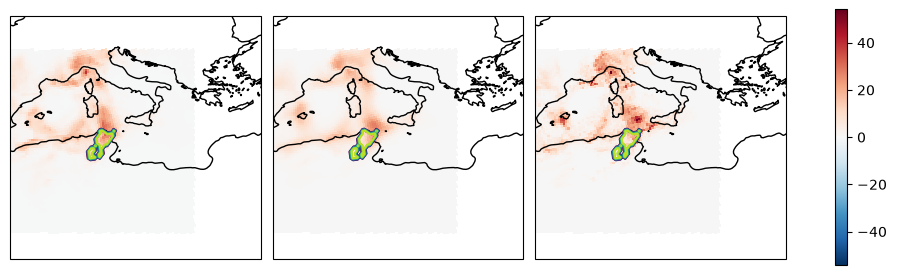

In [129]:
ds_ = all_ds[2]
ds_plot= ds_[['observation','forecast_aifs','forecast_ifs_control']].to_array('data_type').isel(init_time=0)
ds_plot = ds_plot.where(ds_plot.sel(data_type='observation').notnull(),)


plot =ds_plot.plot(col='data_type',subplot_kws=dict(projection=POLAR), transform=ccrs.PlateCarree())
for ax in plot.axs.flat:
    ax.coastlines()
    ds_.event_mask.plot.contour(ax=ax, transform=ccrs.PlateCarree())
    

In [ ]:
import numpy as np
from scipy.ndimage import uniform_filter

def fractions(binary, valid, size):
    num = uniform_filter(np.where(valid, binary, 0).astype(float), size=size, mode="constant")
    den = uniform_filter(valid.astype(float), size=size, mode="constant")
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.where(den > 0, num / den, np.nan)

def fss_parts(fcst_bin, obs_bin, valid, size):
    Pf = fractions(fcst_bin, valid, size)
    Po = fractions(obs_bin, valid, size)
    m = valid & np.isfinite(Pf) & np.isfinite(Po)
    num = np.sum((Pf[m] - Po[m])**2)
    den = np.sum(Pf[m]**2) + np.sum(Po[m]**2)
    return num, den          # FSS = 1 - num/den

def get_results(ds):

    # frequency-matched forecast event
    all_aifs_fss = []
    all_ifs_fss = []
    obs = ds_.observation.values
    obs_mask = ds_.event_mask.fillna(0).values.astype(bool)
    sizes = [(1, 1), (3, 5), (5, 9), (9, 17)]          # adapt to your grid spacing, in km
    models = {"ifs": ds_.forecast_ifs_control, "aifs": ds_.forecast_aifs}

    results = []   # one row per (model, init, size)
    for name, da in models.items():
        for k in range(da.sizes["init_time"]):
            fc = da.isel(init_time=k).values
            valid = np.isfinite(obs) & np.isfinite(fc)
            f0 = obs_mask[valid].mean()
            thr = np.quantile(fc[valid], 1 - f0)
            fc_bin = (fc > thr) if thr == 0 else (fc >= thr)
            for s in sizes:
                num, den = fss_parts(fc_bin, obs_mask, valid, size=s)
                results.append(dict(model=name, init=da.init_time.values[k],
                                    size=s, num=num, den=den, fss=1 - num / den,
                                    thr=thr, fcst_frac=fc_bin[valid].mean(), f0=f0))
    return df = pd.DataFrame(results)


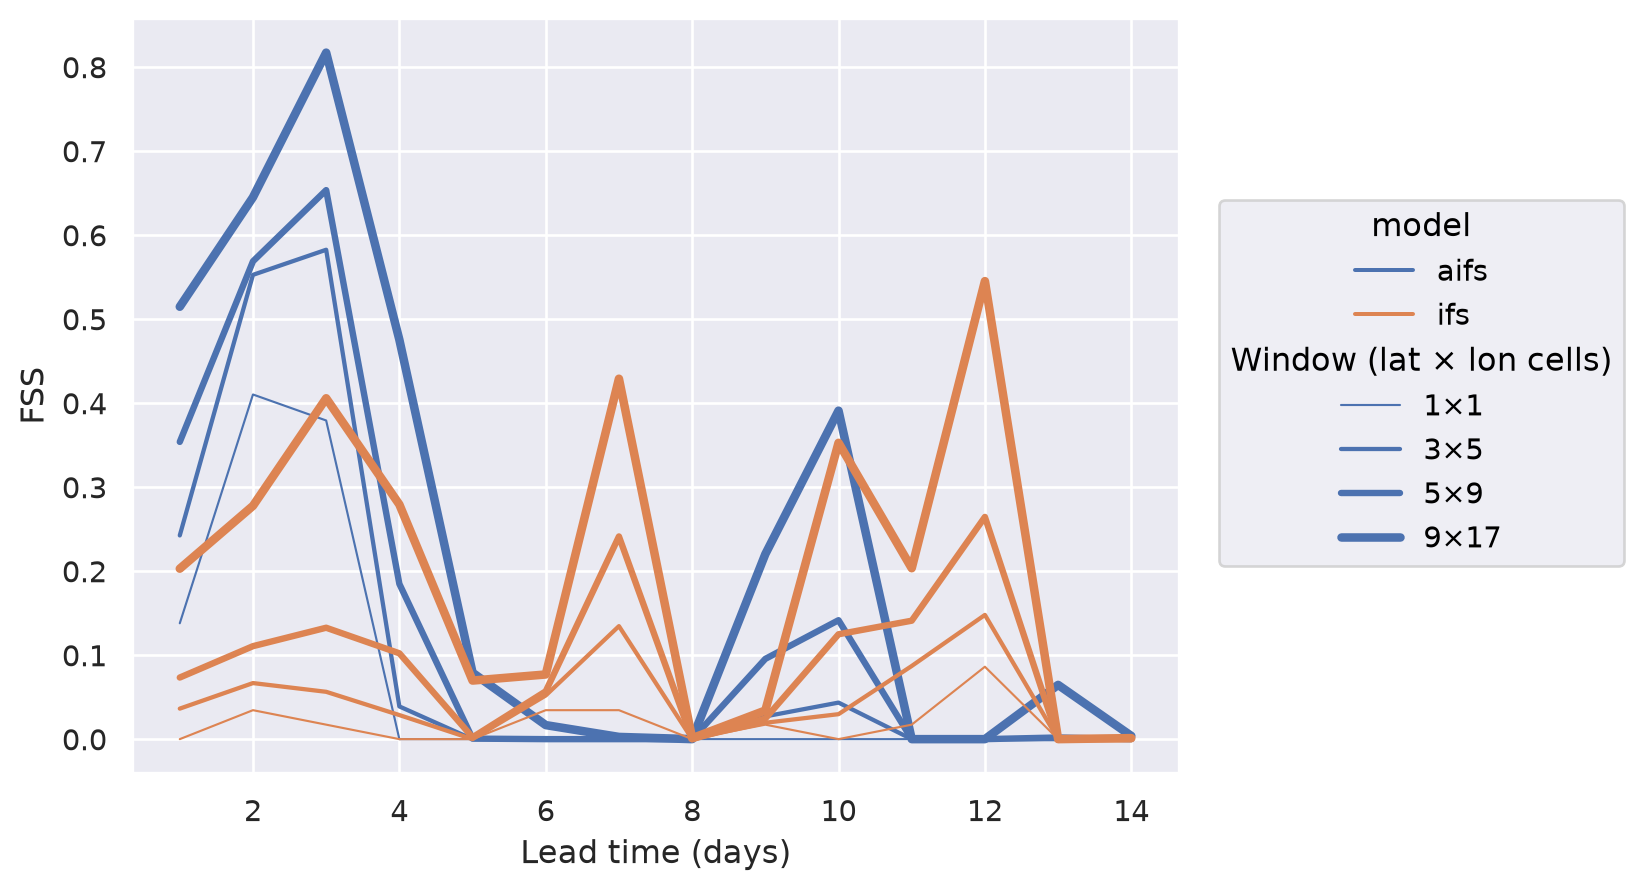

In [132]:
import seaborn.objects as so
df = pd.DataFrame(results)

order = ["1×1", "3×5", "5×9", "9×17"]
event_day = pd.to_datetime(ds_.attrs['event_day'])
df = df.assign(
    window=df["size"].map(lambda s: f"{s[0]}×{s[1]}"),
    lead=(event_day - df["init"]).dt.days,   # or store lead_days from the NetCDF directly
)

# pooled FSS over events: sum numerators and denominators, then 1 - num/den
agg = (df.groupby(["model", "window", "lead"], as_index=False)[["num", "den"]].sum()
         .assign(fss=lambda d: 1 - d["num"] / d["den"]))

(
    so.Plot(agg, x="lead", y="fss", color="model", linewidth="window")
    .add(so.Line())
    .scale(linewidth=so.Nominal([0.8, 1.6, 2.4, 3.2], order=order))
    .label(x="Lead time (days)", y="FSS", linewidth="Window (lat × lon cells)")
)

<Axes: xlabel='init'>

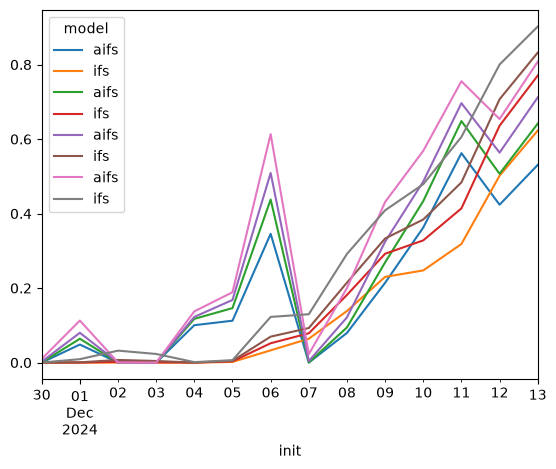

In [106]:
df = pd.DataFrame(results)
df.loc[df['size']==(1, 1)].pivot(index='init', columns='model', values='fss').plot()
df.loc[df['size']==(3, 5)].pivot(index='init', columns='model', values='fss').plot(ax=plt.gca())
df.loc[df['size']==(5, 9)].pivot(index='init', columns='model', values='fss').plot(ax=plt.gca())
df.loc[df['size']==(9, 17)].pivot(index='init', columns='model', values='fss').plot(ax=plt.gca())

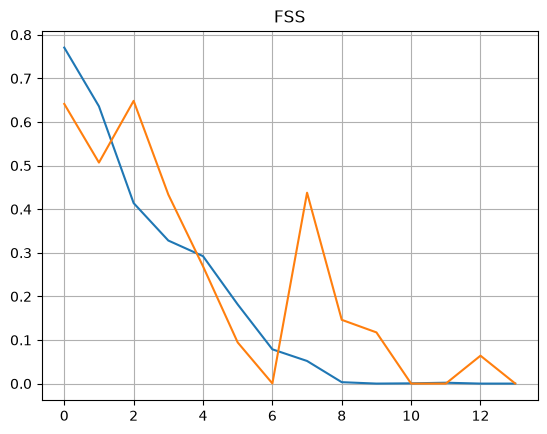

In [83]:
plt.plot(all_ifs_fss, label='IFS')
plt.plot(all_aifs_fss, label='AIFS')
plt.title('FSS')
plt.grid()

In [62]:
ds_

<xarray.Dataset> Size: 121MB
Dimensions:               (latitude: 100, longitude: 203, init_time: 14,
                           ensemble_member: 51)
Coordinates:
  * latitude              (latitude) float64 800B 73.25 73.0 ... 48.75 48.5
  * longitude             (longitude) float64 2kB 2.25 2.5 2.75 ... 52.5 52.75
  * init_time             (init_time) datetime64[ns] 112B 2024-12-13 ... 2024...
    lead_days             (init_time) int64 112B ...
    aifs_v1               (init_time) bool 14B ...
  * ensemble_member       (ensemble_member) int16 102B 0 1 2 3 4 ... 47 48 49 50
Data variables:
    observation           (latitude, longitude) float64 162kB nan nan ... nan
    event_mask            (latitude, longitude) int8 20kB 0 0 0 0 0 ... 0 0 0 0
    forecast_aifs         (init_time, latitude, longitude) float64 2MB ...
    forecast_ifs_control  (init_time, latitude, longitude) float64 2MB ...
    forecast_ifs_ens      (init_time, ensemble_member, latitude, longitude) float64 116MB ...
Attributes: (12/14)
    event_day:           2024-12-14
    sid:                 253
    cyclone_depth_max:   18.0
    event_area_km2:      212161.7441982026
    n_objects:           2
    centre_lat:          61.839094280235834
    ...                  ...
    rain_max:            20.877870354180853
    n_event_cells:       578
    box_polar_bounds_m:  [  146712.45145915 -3834042.75660902  2421833.362821...
    box_crs:             EPSG:6931
    heavy_definition:    ERA5 > local P95 and > 10.0 mm, land
    attribution:         object area overlap with CNECT storm-radius footprin...

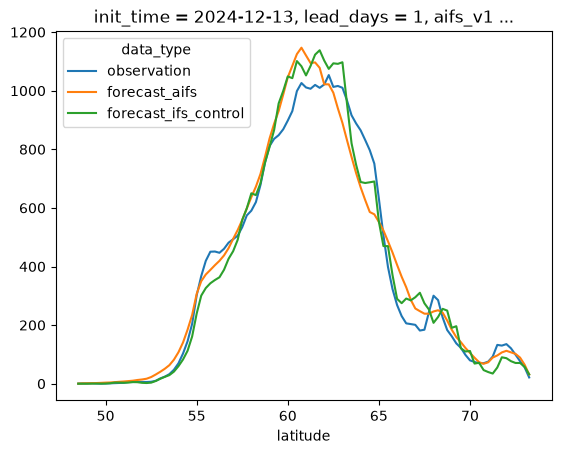

In [47]:
ds_plot.sum('longitude').plot(hue='data_type')

In [ ]:
ds_plot.where(ds_plot.observatoin)

<xarray.DataArray (data_type: 3, latitude: 100, longitude: 203)> Size: 487kB
array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]]], shape=(3, 100, 203))
Coordinates:
  * data_type  (data_type) object 24B 'observation' ... 'forecast_ifs_control'
  * latitude   (latitude) float64 800B 73.25 73.0 72.75 72.5 ... 49.0 48.75 48.5
  * longitude  (longitude) float64 2kB 2.25 2.5 2.75 3.0 ... 52.25 52.5 52.75
    init_time  datetime64[ns] 8B 2024-12-13
    lead_days  int64 8B 1
    aifs_v1    bool 1B False
Attributes: (12/14)
    event_day:           2024-12-14
    sid:                 253
    cyclone_depth_max:   18.0
    event_area_km2:      212161.7441982026
    n_objects:           2
    centre_lat:          61.839094280235834
    ...                  ...
    rain_max:            20.877870354180853
    n_event_cells:       578
    box_polar_bounds_m:  [  146712.45145915 -3834042.75660902  2421833.362821...
    box_crs:             EPSG:6931
    heavy_definition:    ERA5 > local P95 and > 10.0 mm, land
    attribution:         object area overlap with CNECT storm-radius footprin...

In [27]:
all_ds[1][['observation','forecast_aifs','forecast_ifs_control']].to_array('data_type')

<xarray.DataArray (data_type: 3, latitude: 100, longitude: 203, init_time: 14)> Size: 7MB
array([[[[       nan,        nan,        nan, ...,        nan,
                 nan,        nan],
         [       nan,        nan,        nan, ...,        nan,
                 nan,        nan],
         [       nan,        nan,        nan, ...,        nan,
                 nan,        nan],
         ...,
         [       nan,        nan,        nan, ...,        nan,
                 nan,        nan],
         [       nan,        nan,        nan, ...,        nan,
                 nan,        nan],
         [       nan,        nan,        nan, ...,        nan,
                 nan,        nan]],

        [[       nan,        nan,        nan, ...,        nan,
                 nan,        nan],
         [       nan,        nan,        nan, ...,        nan,
                 nan,        nan],
         [       nan,        nan,        nan, ...,        nan,
                 nan,        nan],
...
         [0.45817494, 0.28187335, 0.49623549, ..., 0.07628202,
          0.71647167, 0.09173155],
         [0.541538  , 0.31237006, 0.41898787, ..., 0.07628202,
          1.20441914, 0.06115437],
         [0.55602193, 0.35887957, 0.41922927, ..., 0.09157062,
          0.961411  , 0.03057718]],

        [[0.64815581, 0.92166066, 1.06135011, ..., 0.97814798,
          1.80244446, 6.93876743],
         [0.67953765, 0.56471229, 1.1973381 , ..., 0.85471272,
          0.74672699, 8.03632736],
         [0.81560612, 0.23632944, 1.28866732, ..., 0.68476796,
          0.39653778, 9.23624039],
         ...,
         [0.55626333, 0.3664434 , 0.40386021, ..., 0.10669827,
          1.42103434, 0.06115437],
         [0.53373277, 0.2974838 , 0.41182637, ..., 0.07644296,
          0.67044497, 0.06115437],
         [0.38124919, 0.25926232, 0.38092732, ..., 0.04586577,
          0.64179897, 0.06115437]]]], shape=(3, 100, 203, 14))
Coordinates:
  * data_type  (data_type) object 24B 'observation' ... 'forecast_ifs_control'
  * latitude   (latitude) float64 800B 73.25 73.0 72.75 72.5 ... 49.0 48.75 48.5
  * longitude  (longitude) float64 2kB 2.25 2.5 2.75 3.0 ... 52.25 52.5 52.75
  * init_time  (init_time) datetime64[ns] 112B 2024-12-13 ... 2024-11-30
    lead_days  (init_time) int64 112B ...
    aifs_v1    (init_time) bool 14B ...
Attributes: (12/14)
    event_day:           2024-12-14
    sid:                 253
    cyclone_depth_max:   18.0
    event_area_km2:      212161.7441982026
    n_objects:           2
    centre_lat:          61.839094280235834
    ...                  ...
    rain_max:            20.877870354180853
    n_event_cells:       578
    box_polar_bounds_m:  [  146712.45145915 -3834042.75660902  2421833.362821...
    box_crs:             EPSG:6931
    heavy_definition:    ERA5 > local P95 and > 10.0 mm, land
    attribution:         object area overlap with CNECT storm-radius footprin...

In [21]:
all_ds[1]

<xarray.Dataset> Size: 121MB
Dimensions:               (latitude: 100, longitude: 203, init_time: 14,
                           ensemble_member: 51)
Coordinates:
  * latitude              (latitude) float64 800B 73.25 73.0 ... 48.75 48.5
  * longitude             (longitude) float64 2kB 2.25 2.5 2.75 ... 52.5 52.75
  * init_time             (init_time) datetime64[ns] 112B 2024-12-13 ... 2024...
    lead_days             (init_time) int64 112B ...
    aifs_v1               (init_time) bool 14B ...
  * ensemble_member       (ensemble_member) int16 102B 0 1 2 3 4 ... 47 48 49 50
Data variables:
    observation           (latitude, longitude) float64 162kB ...
    event_mask            (latitude, longitude) int8 20kB ...
    forecast_aifs         (init_time, latitude, longitude) float64 2MB ...
    forecast_ifs_control  (init_time, latitude, longitude) float64 2MB ...
    forecast_ifs_ens      (init_time, ensemble_member, latitude, longitude) float64 116MB ...
Attributes: (12/14)
    event_day:           2024-12-14
    sid:                 253
    cyclone_depth_max:   18.0
    event_area_km2:      212161.7441982026
    n_objects:           2
    centre_lat:          61.839094280235834
    ...                  ...
    rain_max:            20.877870354180853
    n_event_cells:       578
    box_polar_bounds_m:  [  146712.45145915 -3834042.75660902  2421833.362821...
    box_crs:             EPSG:6931
    heavy_definition:    ERA5 > local P95 and > 10.0 mm, land
    attribution:         object area overlap with CNECT storm-radius footprin...

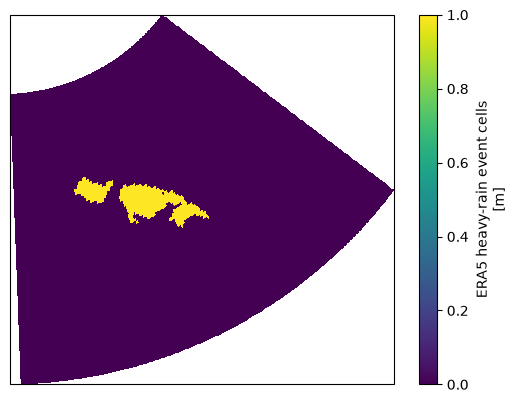

In [16]:
all_ds[1].event_mask.plot(subplot_kws=dict(projection=POLAR), transform=ccrs.PlateCarree())

In [5]:

from event_metrics import event_metrics

all_df_eval = []
for k in tqdm(range(len(all_ds))):
    df = event_metrics(all_ds[k].forecast, all_ds[k].observation, event_day=all_ds[k].time.values)
    all_df_eval.append(df)
all_df_eval = pd.concat(all_df_eval)

  0%|          | 0/194 [00:00<?, ?it/s]

In [6]:
all_df_eval['lead_days'] = -all_df_eval['lead_days'].astype(int)

In [33]:
all_df_eval.skilful_scale_km

init_time
2025-01-31      inf
2025-02-01      inf
2025-02-02      inf
2025-02-03      inf
2025-02-04      inf
              ...  
2025-01-15     25.0
2025-01-16    400.0
2025-01-17     25.0
2025-01-18     25.0
2025-01-19     25.0
Name: skilful_scale_km, Length: 2500, dtype: float64

In [1]:
import numpy as np
from matplotlib.colors import LogNorm
import seaborn.objects as so
(so.Plot(all_df_eval.dropna(), x='lead_days', )
 .add(so.Bar(), so.Count(), so.Stack(), color='skilful_scale_km')
 .scale(color = so.Continuous('crest',trans='sqrt' ))

 )
# plt.title('Skillful Scale (km) quantiles')


NameError: name 'all_df_eval' is not defined

In [53]:
all_df_eval

,lead_days,obs_mean,fcst_mean,amount_ratio,MAE,RMSE,pattern_corr,max_ratio,POD_10,FAR_10,...,FSS_20mm_50km,FSS_20mm_100km,FSS_20mm_200km,FSS_20mm_400km,centroid_dist_km_20mm,SAL_S,SAL_A,SAL_L,SAL_L1,SAL_L2
init_time,,,,,,,,,,,,,,,,,,,,,
2025-01-31,-14,6.775637,2.393717,0.353283,6.635943,9.080789,0.019525,0.918835,0.111239,0.691048,...,3.139235e-03,0.007917,0.015435,0.058718,999.225450,-0.950282,-0.955775,0.225108,0.170347,0.054760
2025-02-01,-13,6.775637,5.459610,0.805771,5.930285,8.687091,0.326097,1.607319,0.326084,0.521440,...,4.137159e-02,0.044518,0.048718,0.058525,817.025371,-0.718665,-0.215121,0.144792,0.109867,0.034925
2025-02-02,-12,6.775637,3.103033,0.457969,6.703802,9.299425,-0.018056,1.024065,0.086594,0.778091,...,2.220446e-16,0.000133,0.002489,0.020463,1064.064925,-0.873289,-0.743542,0.250235,0.147222,0.103013
2025-02-03,-11,6.775637,5.404111,0.797580,7.904015,12.250739,0.086358,1.896793,0.224470,0.591452,...,1.644465e-02,0.014366,0.013417,0.015822,981.105313,-0.882820,-0.225214,0.207706,0.163656,0.044051
2025-02-04,-10,6.775637,1.725965,0.254731,6.174610,8.510894,-0.109646,0.594163,0.004745,0.912080,...,0.000000e+00,0.000000,0.000000,0.000000,NaN,-1.193139,-1.187934,0.416895,0.039149,0.377746
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-01-15,-6,2.636972,2.911689,1.104179,1.274911,2.384248,0.829501,0.643234,0.646128,0.391048,...,5.347786e-01,0.580031,0.587767,0.595530,70.713113,0.577454,0.099021,0.055797,0.029258,0.026539
2025-01-16,-5,2.636972,2.547424,0.966041,1.781878,3.675100,0.557294,0.452174,0.317020,0.651156,...,2.735978e-02,0.045370,0.060762,0.070074,394.932087,0.771056,-0.034545,0.067531,0.038202,0.029328
2025-01-17,-4,2.636972,2.751732,1.043520,1.378022,2.705150,0.776334,0.665524,0.589644,0.424276,...,4.702615e-01,0.521156,0.546407,0.551922,39.062543,0.480313,0.042593,0.047144,0.029785,0.017359


In [41]:
all_df_eval.groupby('lead_days').skilful_scale_km.quantile(np.arange(0,1.01,.05)).unstack()

,0.00,0.05,0.10,0.15,0.20,0.25,0.30,0.35,0.40,0.45,...,0.55,0.60,0.65,0.70,0.75,0.80,0.85,0.90,0.95,1.00
lead_days,,,,,,,,,,,,,,,,,,,,,
-14,25.0,50.0,200.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,inf
-13,25.0,50.0,400.0,400.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,inf
-12,25.0,50.0,100.0,400.0,400.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,inf
-11,25.0,25.0,50.0,200.0,400.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,inf
-10,25.0,25.0,50.0,100.0,200.0,400.0,400.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,inf
-9,25.0,25.0,25.0,50.0,200.0,350.0,400.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,inf
-8,25.0,25.0,25.0,25.0,50.0,50.0,100.0,200.00,400.0,400.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,inf
-7,25.0,25.0,25.0,25.0,25.0,50.0,50.0,100.00,200.0,400.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,inf
-6,25.0,25.0,25.0,25.0,25.0,25.0,25.0,46.25,50.0,97.5,...,200.0,400.0,400.0,400.0,NaN,NaN,NaN,NaN,NaN,inf


ValueError: cannot reindex on an axis with duplicate labels

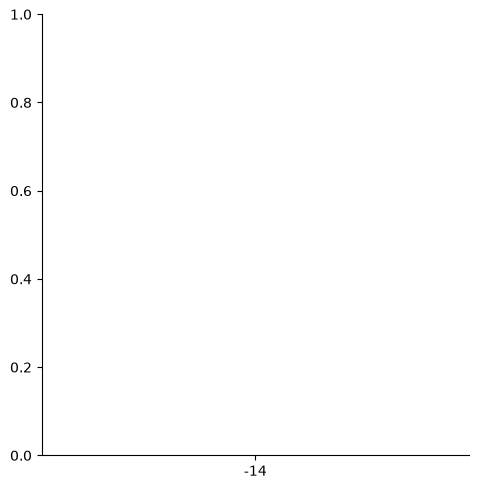

In [9]:
sns.catplot(all_df_eval, x='lead_days', y='FSS_20mm_100km', kind='box')
plt.grid()